In [1]:
import os
import urllib.request
import tarfile

# Create a folder for the dataset
os.makedirs("/content/email_dataset", exist_ok=True)

# Dataset download links
urls = {
    "easy_ham": "https://spamassassin.apache.org/old/publiccorpus/20030228_easy_ham.tar.bz2",
    "spam": "https://spamassassin.apache.org/old/publiccorpus/20030228_spam.tar.bz2"
}

# Download and extract each dataset
for name, url in urls.items():
    archive_path = f"/content/{name}.tar.bz2"

    print(f"Downloading {name} dataset...")

    urllib.request.urlretrieve(url, archive_path)

    print(f"Extracting {name} dataset...")

    with tarfile.open(archive_path, "r:bz2") as tar:
        tar.extractall("/content/email_dataset", filter="data")

    print(f"{name} completed!")

print("Dataset downloaded and extracted successfully!")

Extracting easy_ham dataset...
easy_ham completed!
Extracting spam dataset...
spam completed!
Dataset downloaded and extracted successfully!


In [2]:
import os
import urllib.request
import tarfile

# Create a folder for the dataset
os.makedirs("/content/email_dataset", exist_ok=True)

# Dataset download links
urls = {
    "easy_ham": "https://spamassassin.apache.org/old/publiccorpus/20030228_easy_ham.tar.bz2",
    "spam": "https://spamassassin.apache.org/old/publiccorpus/20030228_spam.tar.bz2"
}

# Download and extract each dataset
for name, url in urls.items():
    archive_path = f"/content/{name}.tar.bz2"

    print(f"Downloading {name} dataset...")

    urllib.request.urlretrieve(url, archive_path)

    print(f"Extracting {name} dataset...")

    with tarfile.open(archive_path, "r:bz2") as tar:
        tar.extractall("/content/email_dataset", filter="data")

    print(f"{name} completed!")

print("Dataset downloaded and extracted successfully!")

Extracting easy_ham dataset...
easy_ham completed!
Extracting spam dataset...
spam completed!
Dataset downloaded and extracted successfully!


In [4]:
import pandas as pd
import os
import email
from email import policy
from email.parser import BytesParser

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
import os
import pandas as pd
from email import policy
from email.parser import BytesParser

emails = []

dataset_path = "/content/email_dataset"

for category in ["easy_ham", "spam"]:
    folder = os.path.join(dataset_path, category)

    if not os.path.exists(folder):
        print("Folder not found:", folder)
        continue

    print("Reading emails from:", category)

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        if not os.path.isfile(filepath):
            continue

        try:
            with open(filepath, "rb") as f:
                msg = BytesParser(policy=policy.default).parse(f)

            subject = str(msg.get("subject", ""))
            body = ""

            if msg.is_multipart():
                for part in msg.walk():
                    if part.get_content_type() == "text/plain":
                        try:
                            content = part.get_content()
                            if isinstance(content, str):
                                body += content
                        except Exception:
                            pass
            else:
                try:
                    content = msg.get_content()
                    if isinstance(content, str):
                        body = content
                except Exception:
                    pass

            message = subject + " " + body

            if message.strip():
                label = "spam" if category == "spam" else "ham"
                emails.append({
                    "message": message,
                    "label": label
                })

        except Exception:
            continue

print("\nEmail extraction completed!")
print("Total emails extracted:", len(emails))

Reading emails from: easy_ham
Reading emails from: spam

Email extraction completed!
Total emails extracted: 3001


In [10]:
df.to_csv("/content/email_spam_dataset.csv", index=False)

print("Dataset saved successfully!")

NameError: name 'df' is not defined

In [11]:
import pandas as pd

# Convert extracted emails into a dataset
df = pd.DataFrame(emails)

# Remove missing and empty messages
df = df.dropna(subset=["message", "label"])
df = df[df["message"].str.strip() != ""]

# Remove duplicate emails
df = df.drop_duplicates(subset=["message"])

# Display dataset information
print("Dataset created successfully!")
print("Total emails:", len(df))

print("\nSpam and non-spam counts:")
print(df["label"].value_counts())

display(df.head())

Dataset created successfully!
Total emails: 2957

Spam and non-spam counts:
label
ham     2473
spam     484
Name: count, dtype: int64


,message,label
0,[SAdev] [Bug 813] add Bayesian spam filtering ...,ham
1,Gearheads and bunnyhuggers in the OED URL: htt...,ham
2,Re: sprint delivers the next big thing?? these...,ham
3,Re: From salon.com - Forbidden thoughts about ...,ham
4,Mac OS X browsers URL: http://www.askbjoernhan...,ham


In [12]:
df.to_csv("/content/email_spam_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [14]:
from google.colab import files

files.download("/content/email_spam_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import pandas as pd

# Convert emails into a DataFrame
df = pd.DataFrame(emails)

# Remove empty emails and duplicates
df = df.dropna(subset=["message", "label"])
df = df[df["message"].str.strip() != ""]
df = df.drop_duplicates(subset=["message"])

print("Dataset created successfully!")
print("Total emails:", len(df))

print("\nSpam and non-spam counts:")
print(df["label"].value_counts())

display(df.head())

Dataset created successfully!
Total emails: 2957

Spam and non-spam counts:
label
ham     2473
spam     484
Name: count, dtype: int64


,message,label
0,[SAdev] [Bug 813] add Bayesian spam filtering ...,ham
1,Gearheads and bunnyhuggers in the OED URL: htt...,ham
2,Re: sprint delivers the next big thing?? these...,ham
3,Re: From salon.com - Forbidden thoughts about ...,ham
4,Mac OS X browsers URL: http://www.askbjoernhan...,ham


In [16]:
df.to_csv("/content/email_spam_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [17]:
print("Dataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate emails:", df["message"].duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 2957 entries, 0 to 3000
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   message  2957 non-null   object
 1   label    2957 non-null   object
dtypes: object(2)
memory usage: 69.3+ KB
None

Missing values:
message    0
label      0
dtype: int64

Duplicate emails: 0


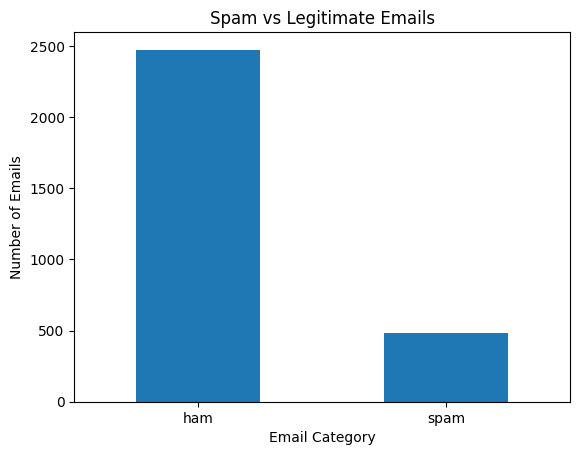

In [18]:
import matplotlib.pyplot as plt

email_counts = df["label"].value_counts()

email_counts.plot(kind="bar")

plt.title("Spam vs Legitimate Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")
plt.xticks(rotation=0)

plt.show()

In [19]:
# Input: email messages
X = df["message"]

# Output: email categories
y = df["label"]

print("Input data prepared!")
print("Total messages:", len(X))
print("Total labels:", len(y))

Input data prepared!
Total messages: 2957
Total labels: 2957


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

Training emails: 2365
Testing emails: 592


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Text converted into numerical features!")
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Text converted into numerical features!
Training data shape: (2365, 20000)
Testing data shape: (592, 20000)


In [22]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB(alpha=0.5)

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [23]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

Predictions completed!

First 10 actual labels:
['ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'spam', 'ham', 'ham', 'spam']

First 10 predicted labels:
['ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'spam']


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)

recall = recall_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:  0.9628
Precision: 1.0000
Recall:    0.7732
F1-score:  0.8721

Detailed classification report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       495
        spam       1.00      0.77      0.87        97

    accuracy                           0.96       592
   macro avg       0.98      0.89      0.93       592
weighted avg       0.96      0.96      0.96       592



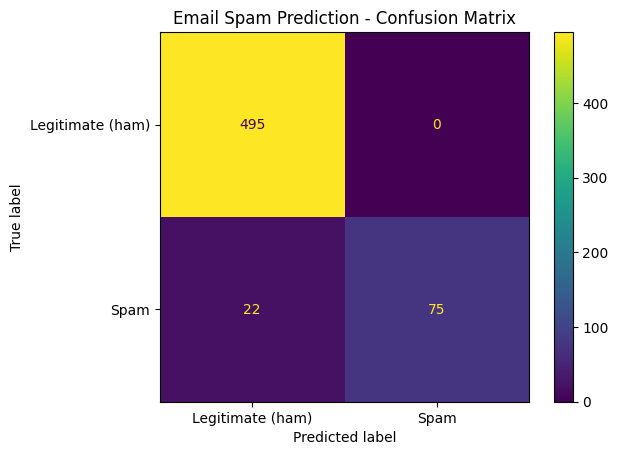

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate (ham)", "Spam"]
)

display_matrix.plot()

plt.title("Email Spam Prediction - Confusion Matrix")
plt.show()

In [28]:
def predict_email(message):
    email_features = vectorizer.transform([message])
    prediction = model.predict(email_features)[0]
    probabilities = model.predict_proba(email_features)[0]

    spam_index = list(model.classes_).index("spam")
    spam_probability = probabilities[spam_index] * 100

    print("Prediction:", prediction.upper())
    print(f"Estimated spam probability: {spam_probability:.2f}%")

    return prediction

In [27]:
sample_email = """
Congratulations! You have won a free prize.
Click here to claim your reward immediately.
"""

predict_email(sample_email)

Prediction: HAM
Estimated spam probability: 31.05%


np.str_('ham')

In [29]:
sample_email = """
Hello, the meeting is scheduled for tomorrow at 10 AM.
Please bring the project report.
"""

predict_email(sample_email)

Prediction: HAM
Estimated spam probability: 3.49%


np.str_('ham')

In [30]:
import joblib

saved_model = {
    "vectorizer": vectorizer,
    "model": model
}

joblib.dump(
    saved_model,
    "/content/email_spam_model.pkl"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [31]:
from google.colab import files

files.download("/content/email_spam_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from google.colab import files

files.download("/content/email_spam_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
files.download("/content/email_spam_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import joblib

saved_model = {
    "vectorizer": vectorizer,
    "model": model
}

joblib.dump(saved_model, "/content/email_spam_model.pkl")

print("Trained model saved successfully!")

Trained model saved successfully!


In [35]:
from google.colab import files

files.download("/content/email_spam_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import os

print(os.path.exists("/content/email_spam_model.pkl"))


True


In [37]:
from google.colab import files

files.download("/content/email_spam_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import os

if os.path.exists("/content/email_spam_model.pkl"):
    print("Model file exists!")
else:
    print("Model file is missing!")

Model file exists!


In [40]:
from google.colab import files

files.download("/content/email_spam_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import joblib
import os

model_path = "/content/email_spam_model.pkl"

print("File exists:", os.path.exists(model_path))

try:
    saved_model = joblib.load(model_path)
    print("Model loaded successfully!")
    print("Model keys:", saved_model.keys())
except Exception as e:
    print("Model loading error:", repr(e))

File exists: True
Model loaded successfully!
Model keys: dict_keys(['vectorizer', 'model'])


In [42]:
import joblib

joblib.dump(
    {
        "vectorizer": saved_model["vectorizer"],
        "model": saved_model["model"]
    },
    "/content/email_spam_model_fixed.pkl"
)

# Verify the newly created file
test_model = joblib.load("/content/email_spam_model_fixed.pkl")

print("New model saved and verified!")
print(test_model.keys())

New model saved and verified!
dict_keys(['vectorizer', 'model'])


In [43]:
from google.colab import files

files.download("/content/email_spam_model_fixed.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import joblib

# Save the trained model and vectorizer together
saved_model = {
    "vectorizer": vectorizer,
    "model": model
}

# Create a fresh model file
joblib.dump(saved_model, "/content/email_spam_model_fixed.pkl")

# Verify that the file can be loaded
test_model = joblib.load("/content/email_spam_model_fixed.pkl")

print("SUCCESS! Model saved and loaded correctly.")
print("Available keys:", list(test_model.keys()))

SUCCESS! Model saved and loaded correctly.
Available keys: ['vectorizer', 'model']


In [45]:
from google.colab import files

files.download("/content/email_spam_model_fixed.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
import joblib
import os

print("Vectorizer exists:", "vectorizer" in globals())
print("Model exists:", "model" in globals())

Vectorizer exists: True
Model exists: True


In [47]:
import joblib

# Save the trained model components
joblib.dump(vectorizer, "/content/spam_vectorizer.pkl")
joblib.dump(model, "/content/spam_classifier.pkl")

# Verify both files
v = joblib.load("/content/spam_vectorizer.pkl")
m = joblib.load("/content/spam_classifier.pkl")

print("SUCCESS! Both model files work.")

SUCCESS! Both model files work.


In [49]:
from google.colab import files

files.download("/content/spam_vectorizer.pkl")
files.download("/content/spam_classifier.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
print("Vectorizer exists:", "vectorizer" in globals())
print("Model exists:", "model" in globals())

Vectorizer exists: True
Model exists: True


In [51]:
import joblib
import os

for filename in ["spam_vectorizer.pkl", "spam_classifier.pkl"]:
    path = "/content/" + filename

    print(f"\nTesting: {filename}")
    print("Exists:", os.path.exists(path))

    try:
        obj = joblib.load(path)
        print("Status: SUCCESS")
        print("Object type:", type(obj))
    except Exception as e:
        print("Status: FAILED")
        print("Error:", repr(e))


Testing: spam_vectorizer.pkl
Exists: True
Status: SUCCESS
Object type: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>

Testing: spam_classifier.pkl
Exists: True
Status: SUCCESS
Object type: <class 'sklearn.naive_bayes.MultinomialNB'>


In [54]:
import zipfile
import os

# Create a ZIP file containing both model files
with zipfile.ZipFile("/content/spam_models.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write("/content/spam_vectorizer.pkl", "spam_vectorizer.pkl")
    z.write("/content/spam_classifier.pkl", "spam_classifier.pkl")

print("ZIP file created successfully!")

ZIP file created successfully!


In [53]:
from google.colab import files

files.download("/content/spam_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
!pip install streamlit scikit-learn joblib pyngrok


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 27.0 MB/s eta 0:00:00


In [56]:
%%writefile app.py

import streamlit as st
import joblib

st.set_page_config(
    page_title="Email Spam Prediction",
    page_icon="📧"
)

st.title("📧 Email Spam Prediction")
st.write("Check whether an email is Spam or Not Spam.")

@st.cache_resource
def load_models():
    vectorizer = joblib.load("/content/spam_vectorizer.pkl")
    model = joblib.load("/content/spam_classifier.pkl")
    return vectorizer, model

vectorizer, model = load_models()

email_text = st.text_area(
    "Enter the email message:",
    height=200,
    placeholder="Type or paste your email here..."
)

if st.button("Predict Email"):
    if email_text.strip():
        transformed_email = vectorizer.transform([email_text])
        prediction = model.predict(transformed_email)[0]

        if str(prediction).lower() == "spam":
            st.error("🚨 This email is SPAM!")
        else:
            st.success("✅ This email is NOT SPAM (HAM).")
    else:
        st.warning("Please enter an email message.")

Writing app.py


In [57]:
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [58]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("Open your Email Spam Prediction application here:")
print(public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-15T06:59:32+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-15T06:59:32+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [60]:
from pyngrok import ngrok

ngrok.kill()

ngrok.set_auth_token("3KikGq0rzJyzCI0L3jD9lc1DnjO_5gfte5dCG17fRbvcFwX7F")

public_url = ngrok.connect(8501)

print("Your application link:", public_url)

Your application link: NgrokTunnel: "https://density-alarm-pristine.ngrok-free.dev" -> "http://localhost:8501"
